In [6]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ["OPENAI_API_KEY"]=os.getenv("OPENAI_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

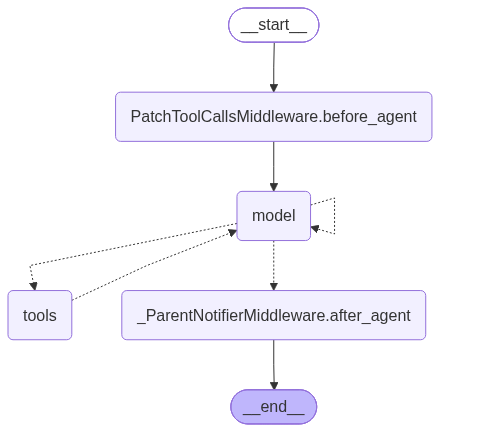

In [9]:
from typing import Literal
from deepagents import create_deep_agent
from tavily import TavilyClient
import tavily

tavily_client = TavilyClient(api_key=os.environ["TAVILY_API_KEY"])

def internet_search(
    query: str,
    max_results: int = 5,
    topic: Literal["general", "news", "finance"] = "general",
    include_raw_content: bool = False
):
    """Run a web search"""
    return tavily_client.search(
        query,
        max_results=max_results,
        include_raw_content=include_raw_content,
        topic=topic
    )

research_subagent = {
    "name": "research-agent",
    "description": "Used to research more in depth questions",
    "system_prompt": "You are a great researcher",
    "tools": [internet_search],
    "model": "openai:gpt-4o-mini"
}

subagents = [research_subagent]

agent = create_deep_agent(
    model="openai:gpt-4o-mini",
    subagents=subagents
)

agent


In [10]:
result = agent.invoke(
    {
        "messages": [{
            "role": "user",
            "content": "Research about LLM Gateways and provide me a detailed summary."
        }]
    },
    config = {"configurable": {"thread_id": "skills-demo-1"}}
)

for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Research about LLM Gateways and provide me a detailed summary.
================================== Ai Message ==================================

[{'arguments': '{"description":"Research the concept of LLM (Large Language Model) Gateways, including how they operate, their applications, advantages, and potential challenges. Provide a detailed summary, including any relevant technologies, standards, and case studies if available.","subagent_type":"research-agent"}', 'call_id': 'call_uf3S5NU3iWV03B8g0Nn7Y4R9', 'name': 'task', 'type': 'function_call', 'id': 'fc_030e3127ae6a03bc006ae9f151874c87d2abccfcfbc44cfe05', 'status': 'completed'}]
Tool Calls:
  task (call_uf3S5NU3iWV03B8g0Nn7Y4R9)
 Call ID: call_uf3S5NU3iWV03B8g0Nn7Y4R9
  Args:
    description: Research the concept of LLM (Large Language Model) Gateways, including how they operate, their applications, advantages, and potential challenges. Provide a detai

## Structured output with sub agents

In [13]:
from pydantic import BaseModel, Field

class ReasearchFinding(BaseModel):
    """Structured findings from a research task"""
    summary: str = Field(description="Summary of findings")
    confidence: float = Field(descriptio="Confidence score from 0 to 1")
    sources: list[str] = Field(description="List of source URLS")

research_subagent = {
    "name": "researcher",
    "description": "Researches topics and returns structured findings",
    "system_prompt": "Research the given topic thoroughly. Return your findings",
    "tools": [internet_search],
    "response_format": ReasearchFinding,
}

agent = create_deep_agent(
    model="openai:gpt-4o-mini",
    subagents=[research_subagent]
)

result = await agent.ainvoke(
    {"messages": [{"role": "user", "content": "Research recent advances in quantum computing"}]}
)

C:\Users\nico_\AppData\Local\Temp\ipykernel_30312\214139202.py:6: PydanticDeprecatedSince20: Using extra keyword arguments on `Field` is deprecated and will be removed. Use `json_schema_extra` instead. (Extra keys: 'descriptio'). Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.14/migration/
  confidence: float = Field(descriptio="Confidence score from 0 to 1")


In [14]:
for m in result["messages"]:
    m.pretty_print()

================================ Human Message =================================

Research recent advances in quantum computing
================================== Ai Message ==================================

[{'arguments': '{"description":"Research recent advances in quantum computing, focusing on key developments, significant breakthroughs, and current trends in the field. Provide a structured summary including the major players, technologies being developed, and potential applications or implications of these advances.","subagent_type":"researcher"}', 'call_id': 'call_Vjjw4RDYNLsGRSwA42tOeDUl', 'name': 'task', 'type': 'function_call', 'id': 'fc_0761edf1a8760bdf006ae9f545fcc887d2869811004f863cea', 'status': 'completed'}]
Tool Calls:
  task (call_Vjjw4RDYNLsGRSwA42tOeDUl)
 Call ID: call_Vjjw4RDYNLsGRSwA42tOeDUl
  Args:
    description: Research recent advances in quantum computing, focusing on key developments, significant breakthroughs, and current trends in the field. Provide a str